In [2]:
import os, sys
from pathlib import Path

PROJECT_ROOT = Path(r"C:\Users\amand\OneDrive - Fisk University\Documents\ResumeBiasResearch")
os.chdir(PROJECT_ROOT)
sys.path.insert(0, str(PROJECT_ROOT))

print("CWD:", os.getcwd())
print("Data exists:", Path("data/processed/prepared_data.npz").exists())

CWD: C:\Users\amand\OneDrive - Fisk University\Documents\ResumeBiasResearch
Data exists: True


Background dataset has 19200 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=19200 when initializing the masker.


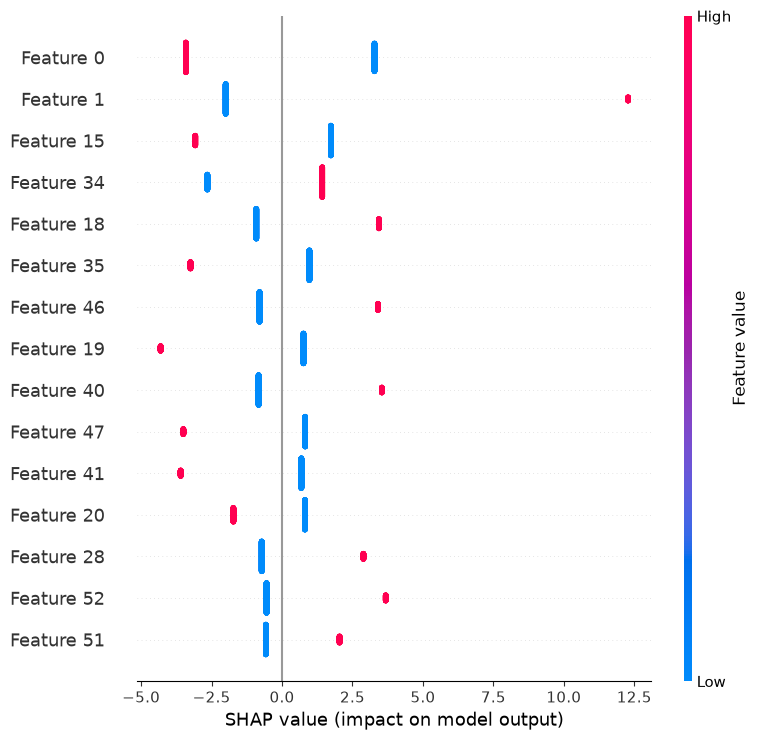

Top-15 features by mean |SHAP value|:
 feature_idx  mean_abs_shap
           0       3.350251
           1       3.047725
          15       2.064705
          34       1.838106
          18       1.516925
          35       1.380697
          46       1.253991
          19       1.246277
          40       1.223974
          47       1.221105
          41       1.142316
          20       1.103651
          28       1.050897
          52       1.028816
          51       0.829345

Note: feature_idx here indexes the 93 encoded features.
The original demographic columns 0 (ethnicity) and 1 (gender)
map to one-hot expansions that should appear in the encoded matrix.


In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import shap
import joblib

data = np.load('data/processed/prepared_data.npz')
X_train, X_test = data['X_train'], data['X_test']
y_train_gender  = data['y_train_gender']

# Load the LR model trained on gender-biased labels
lr = joblib.load('results/models/logistic_regression_blind.pkl')

# Retrain on gender-biased labels (the .pkl was trained on Blind)
from sklearn.linear_model import LogisticRegression
lr_gender = LogisticRegression(max_iter=2000, class_weight='balanced',
                                random_state=42)
lr_gender.fit(X_train, y_train_gender)

# SHAP on a sample of 1000 test profiles
sample_idx = np.random.RandomState(42).choice(len(X_test), 1000, replace=False)
X_sample = X_test[sample_idx]

explainer = shap.LinearExplainer(lr_gender, X_train)
shap_values = explainer.shap_values(X_sample)

# Summary plot
plt.figure()
shap.summary_plot(shap_values, X_sample, max_display=15, show=False)
plt.tight_layout()
plt.savefig('results/figures/07_shap_summary_gender.png', dpi=100, bbox_inches='tight')
plt.show()

# Feature importance ranking
mean_abs_shap = np.abs(shap_values).mean(axis=0)
importance = pd.DataFrame({
    'feature_idx': np.arange(len(mean_abs_shap)),
    'mean_abs_shap': mean_abs_shap,
}).sort_values('mean_abs_shap', ascending=False).head(15)

print("Top-15 features by mean |SHAP value|:")
print(importance.to_string(index=False))

# Check: do the demographic columns (pre-encoding) appear in top features?
# Note: after one-hot encoding, col 0 and col 1 are expanded.
# This check maps back to the original features.
print("\nNote: feature_idx here indexes the 93 encoded features.")
print("The original demographic columns 0 (ethnicity) and 1 (gender)")
print("map to one-hot expansions that should appear in the encoded matrix.")